In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

df = pd.read_csv("../data/raw/fraud_oracle.csv")

X = df.drop(
    columns=["FraudFound_P", "PolicyNumber", "RepNumber"]
)

y = df["FraudFound_P"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (12336, 30)
Testing: (3084, 30)


In [2]:
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_train)

print("Baseline classification results:")
print(classification_report(y_train, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_train, y_pred))

Baseline classification results:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97     11598
           1       0.00      0.00      0.00       738

    accuracy                           0.94     12336
   macro avg       0.47      0.50      0.48     12336
weighted avg       0.88      0.94      0.91     12336

Confusion matrix:
[[11598     0]
 [  738     0]]


In [3]:
baseline_accuracy = accuracy_score(y_train, y_pred)
baseline_precision = precision_score(y_train, y_pred, zero_division=0)
baseline_recall = recall_score(y_train, y_pred, zero_division=0)
baseline_f1 = f1_score(y_train, y_pred, zero_division=0)

baseline_pr_auc = average_precision_score(
    y_train,
    baseline.predict_proba(X_train)[:, 1]
)

print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall: {baseline_recall:.4f}")
print(f"F1-score: {baseline_f1:.4f}")
print(f"Average Precision: {baseline_pr_auc:.4f}")

Accuracy: 0.9402
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000
Average Precision: 0.0598


In [4]:
print("Current features:")
print(X_train.columns.tolist())

print("\nUnique values for selected features:")

for col in ["Year", "PoliceReportFiled", "WitnessPresent", "AgentType"]:
    print(f"\n{col}:")
    print(X_train[col].value_counts())

Current features:
['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year', 'BasePolicy']

Unique values for selected features:

Year:
Year
1994    4949
1995    4152
1996    3235
Name: count, dtype: int64

PoliceReportFiled:
PoliceReportFiled
No     12004
Yes      332
Name: count, dtype: int64

WitnessPresent:
WitnessPresent
No     12266
Yes       70
Name: count, dtype: int64

AgentType:
AgentType
External    12132
Internal      204
Name: count, dtype: int64


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

X_train = X_train.copy()
X_test = X_test.copy()

X_train["Age"] = X_train["Age"].replace(0, np.nan)
X_test["Age"] = X_test["Age"].replace(0, np.nan)

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

categorical_features += ["Year", "DriverRating"]

numerical_features = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in categorical_features
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Model preprocessing pipeline ready")

Model preprocessing pipeline ready


In [9]:
decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

decision_tree.fit(X_train, y_train)

y_train_pred = decision_tree.predict(X_train)

print("Decision Tree — Training Results")
print(classification_report(
    y_train,
    y_train_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

Decision Tree — Training Results
              precision    recall  f1-score   support

           0       1.00      0.61      0.76     11598
           1       0.13      0.95      0.23       738

    accuracy                           0.63     12336
   macro avg       0.56      0.78      0.50     12336
weighted avg       0.94      0.63      0.72     12336


Confusion Matrix:
[[7056 4542]
 [  35  703]]


In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    decision_tree,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    }
)

for metric in [
    "precision",
    "recall",
    "f1",
    "average_precision"
]:
    values = scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} (+/- {values.std():.4f})")

precision: 0.1317 (+/- 0.0040)
recall: 0.9309 (+/- 0.0153)
f1: 0.2308 (+/- 0.0064)
average_precision: 0.1892 (+/- 0.0162)


In [11]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_train)

print("Logistic Regression — Training Results")
print(classification_report(
    y_train,
    logistic_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, logistic_pred))

Logistic Regression — Training Results
              precision    recall  f1-score   support

           0       0.99      0.64      0.78     11598
           1       0.14      0.90      0.24       738

    accuracy                           0.66     12336
   macro avg       0.56      0.77      0.51     12336
weighted avg       0.94      0.66      0.75     12336


Confusion Matrix:
[[7422 4176]
 [  72  666]]


In [12]:
logistic_scores = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    }
)

print("Logistic Regression — Cross-Validation")

for metric in ["precision", "recall", "f1", "average_precision"]:
    values = logistic_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} (+/- {values.std():.4f})")

Logistic Regression — Cross-Validation
precision: 0.1331 (+/- 0.0053)
recall: 0.8509 (+/- 0.0191)
f1: 0.2302 (+/- 0.0085)
average_precision: 0.1509 (+/- 0.0110)


In [13]:
from sklearn.naive_bayes import GaussianNB
from sklearn.base import clone

nb_preprocessor = clone(preprocessor)
nb_preprocessor.set_params(cat__encoder__sparse_output=False)

naive_bayes_model = Pipeline([
    ("preprocessor", nb_preprocessor),
    ("classifier", GaussianNB())
])

naive_bayes_model.fit(X_train, y_train)

nb_pred = naive_bayes_model.predict(X_train)

print("Naive Bayes — Training Results")
print(classification_report(
    y_train,
    nb_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, nb_pred))

Naive Bayes — Training Results
              precision    recall  f1-score   support

           0       0.99      0.05      0.10     11598
           1       0.06      0.99      0.12       738

    accuracy                           0.11     12336
   macro avg       0.53      0.52      0.11     12336
weighted avg       0.93      0.11      0.10     12336


Confusion Matrix:
[[  598 11000]
 [    7   731]]


In [14]:
nb_scores = cross_validate(
    naive_bayes_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    }
)

print("Naive Bayes — Cross-Validation")

for metric in ["precision", "recall", "f1", "average_precision"]:
    values = nb_scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.4f} (+/- {values.std():.4f})")

Naive Bayes — Cross-Validation
precision: 0.0610 (+/- 0.0011)
recall: 0.9648 (+/- 0.0199)
f1: 0.1147 (+/- 0.0021)
average_precision: 0.0662 (+/- 0.0042)


In [15]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)

rf_train_pred = random_forest.predict(X_train)

print("Random Forest — Training Results")
print(classification_report(
    y_train,
    rf_train_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, rf_train_pred))

Random Forest — Training Results
              precision    recall  f1-score   support

           0       1.00      0.65      0.79     11598
           1       0.15      0.97      0.26       738

    accuracy                           0.67     12336
   macro avg       0.57      0.81      0.52     12336
weighted avg       0.95      0.67      0.75     12336


Confusion Matrix:
[[7513 4085]
 [  25  713]]


In [16]:
rf_scores = cross_validate(
    random_forest,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    },
    n_jobs=-1
)

print("Random Forest — Cross-Validation")

for metric in ["precision", "recall", "f1", "average_precision"]:
    values = rf_scores[f"test_{metric}"]
    print(
        f"{metric}: {values.mean():.4f} "
        f"(+/- {values.std():.4f})"
    )

Random Forest — Cross-Validation
precision: 0.1372 (+/- 0.0017)
recall: 0.8781 (+/- 0.0174)
f1: 0.2372 (+/- 0.0028)
average_precision: 0.2199 (+/- 0.0247)


In [17]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

rf_search = RandomizedSearchCV(
    estimator=random_forest,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation average precision:")
print(round(rf_search.best_score_, 4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': None, 'classifier__class_weight': 'balanced_subsample'}

Best cross-validation average precision:
0.2404


In [18]:
best_rf = rf_search.best_estimator_

print("Best Random Forest configuration:")
print(best_rf.named_steps["classifier"])

print("\nTraining classification results:")
best_rf_train_pred = best_rf.predict(X_train)

print(classification_report(
    y_train,
    best_rf_train_pred,
    zero_division=0
))

Best Random Forest configuration:
RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=2,
                       min_samples_split=5, n_jobs=-1, random_state=42)

Training classification results:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     11598
           1       0.98      1.00      0.99       738

    accuracy                           1.00     12336
   macro avg       0.99      1.00      0.99     12336
weighted avg       1.00      1.00      1.00     12336



In [19]:
from sklearn.base import clone

tuned_rf_scores = cross_validate(
    clone(best_rf),
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    },
    n_jobs=-1
)

print("Tuned Random Forest — Cross-Validation")

for metric in ["precision", "recall", "f1", "average_precision"]:
    values = tuned_rf_scores[f"test_{metric}"]
    print(
        f"{metric}: {values.mean():.4f} "
        f"(+/- {values.std():.4f})"
    )

Tuned Random Forest — Cross-Validation
precision: 0.4429 (+/- 0.1000)
recall: 0.0515 (+/- 0.0153)
f1: 0.0919 (+/- 0.0262)
average_precision: 0.2404 (+/- 0.0195)


In [20]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

rf_oof_proba = cross_val_predict(
    clone(best_rf),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold probabilities generated successfully")

Out-of-fold probabilities generated successfully


In [21]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

threshold_results = []

for threshold in thresholds:
    predictions = (rf_oof_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1
0,0.1,0.1291,0.9377,0.2270
1,0.2,0.1667,0.6843,0.2680
2,0.3,0.2323,0.3415,0.2765
3,0.4,0.3531,0.1531,0.2136
4,0.5,0.4419,0.0515,0.0922


In [22]:
potential_leakage_features = [
    "Fault",
    "PoliceReportFiled",
    "WitnessPresent"
]

print("Potential leakage features:")
for col in potential_leakage_features:
    print(col, "-", col in X_train.columns)

X_train_safe = X_train.drop(
    columns=potential_leakage_features,
    errors="ignore"
).copy()

X_test_safe = X_test.drop(
    columns=potential_leakage_features,
    errors="ignore"
).copy()

print("\nTraining shape:", X_train_safe.shape)
print("Testing shape:", X_test_safe.shape)

Potential leakage features:
Fault - True
PoliceReportFiled - True
WitnessPresent - True

Training shape: (12336, 27)
Testing shape: (3084, 27)


In [23]:
from sklearn.base import clone

categorical_safe = X_train_safe.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

categorical_safe += ["Year", "DriverRating"]

numeric_safe = [
    col for col in X_train_safe.select_dtypes(include="number").columns
    if col not in categorical_safe
]

safe_preprocessor = ColumnTransformer([
    ("num", clone(numeric_transformer), numeric_safe),
    ("cat", clone(categorical_transformer), categorical_safe)
])

print("Safe preprocessing pipeline created")
print("Categorical features:", len(categorical_safe))
print("Numerical features:", len(numeric_safe))

Safe preprocessing pipeline created
Categorical features: 23
Numerical features: 4


In [24]:
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

safe_rf = Pipeline([
    ("preprocessor", safe_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

safe_scores = cross_validate(
    safe_rf,
    X_train_safe,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "average_precision": "average_precision"
    },
    n_jobs=-1
)

print("Random Forest without potential leakage features")

for metric in ["precision", "recall", "f1", "average_precision"]:
    values = safe_scores[f"test_{metric}"]
    print(
        f"{metric}: {values.mean():.4f} "
        f"(+/- {values.std():.4f})"
    )

Random Forest without potential leakage features
precision: 0.1127 (+/- 0.0080)
recall: 0.6436 (+/- 0.0479)
f1: 0.1918 (+/- 0.0135)
average_precision: 0.1646 (+/- 0.0113)


In [25]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

safe_oof_proba = cross_val_predict(
    clone(safe_rf),
    X_train_safe,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    predictions = (safe_oof_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, predictions, zero_division=0
        )
    })

safe_threshold_df = pd.DataFrame(threshold_results)

display(safe_threshold_df.round(4))

print(
    "Out-of-fold average precision:",
    round(average_precision_score(y_train, safe_oof_proba), 4)
)

,Threshold,Precision,Recall,F1
0,0.1,0.0773,0.9715,0.1433
1,0.2,0.0844,0.9580,0.1552
2,0.3,0.0851,0.9553,0.1563
3,0.4,0.0908,0.9268,0.1653
4,0.5,0.1127,0.6436,0.1918
5,0.6,0.1842,0.2154,0.1986
6,0.7,0.3452,0.0393,0.0706


Out-of-fold average precision: 0.1591


In [26]:
final_rf = clone(safe_rf)

final_rf.fit(X_train_safe, y_train)

test_probabilities = final_rf.predict_proba(X_test_safe)[:, 1]

final_threshold = 0.60
test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

print("Final Random Forest — Test Results")
print(classification_report(
    y_test,
    test_predictions,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nAverage Precision:")
print(round(
    average_precision_score(y_test, test_probabilities),
    4
))

Final Random Forest — Test Results
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      2899
           1       0.17      0.22      0.19       185

    accuracy                           0.89      3084
   macro avg       0.56      0.57      0.56      3084
weighted avg       0.90      0.89      0.90      3084


Confusion Matrix:
[[2701  198]
 [ 145   40]]

Average Precision:
0.1588


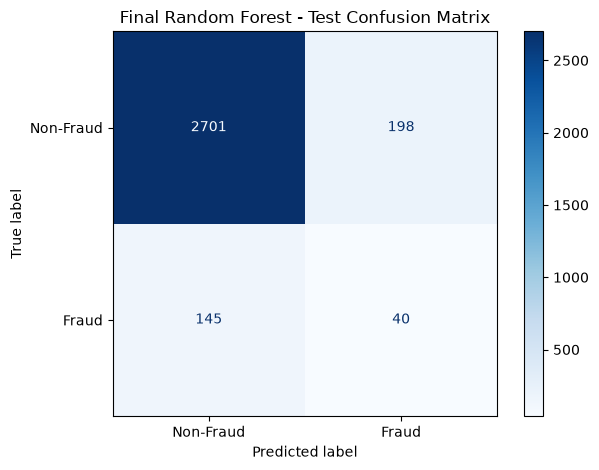

In [28]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Non-Fraud", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Final Random Forest - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [29]:

model_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Logistic Regression",
        "Gaussian Naive Bayes",
        "Original Random Forest",
        "Tuned Random Forest",
        "Original MLP",
        "Regularized MLP",
        "Reduced-Feature Random Forest"
    ],
    "CV F1": [
        0.2308,
        0.2302,
        0.1147,
        0.2372,
        0.0919,
        0.2023,
        0.2106,
        0.1918
    ],
    "CV Average Precision": [
        0.1892,
        0.1509,
        0.0662,
        0.2199,
        0.2404,
        0.1836,
        0.1636,
        0.1646
    ]
})

display(model_comparison.round(4))


,Model,CV F1,CV Average Precision
0,Decision Tree,0.2308,0.1892
1,Logistic Regression,0.2302,0.1509
2,Gaussian Naive Bayes,0.1147,0.0662
3,Original Random Forest,0.2372,0.2199
4,Tuned Random Forest,0.0919,0.2404
5,Original MLP,0.2023,0.1836
6,Regularized MLP,0.2106,0.1636
7,Reduced-Feature Random Forest,0.1918,0.1646


In [30]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

final_results = pd.DataFrame([{
    "Model": "Reduced-Feature Random Forest",
    "Threshold": final_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Fraud Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Fraud Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "Fraud F1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test, test_probabilities
    )
}])

print("Final Held-Out Test Results")
display(final_results.round(4))


Final Held-Out Test Results


,Model,Threshold,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,Average Precision
0,Reduced-Feature Random Forest,0.6,0.8888,0.1681,0.2162,0.1891,0.1588


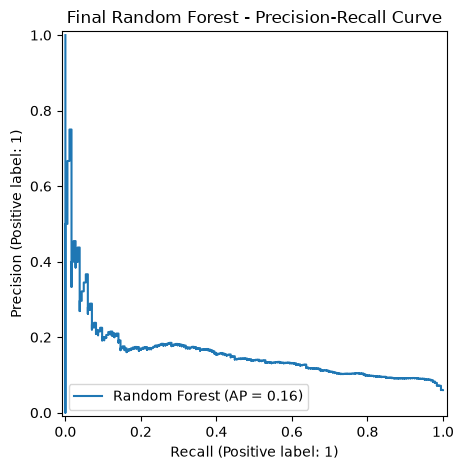

In [31]:

import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Random Forest"
)

plt.title("Final Random Forest - Precision-Recall Curve")
plt.tight_layout()
plt.show()


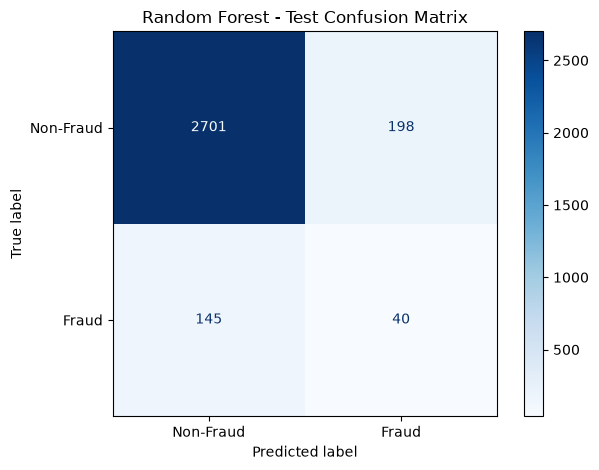

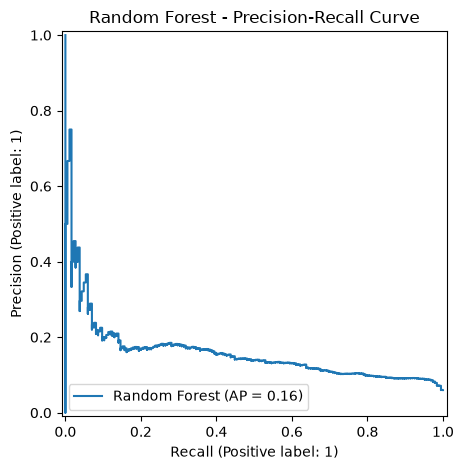

Evaluation figures saved successfully


In [32]:

from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

results_dir = Path("../results/tabular")
results_dir.mkdir(parents=True, exist_ok=True)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["Non-Fraud", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    results_dir / "rf_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Random Forest"
)

plt.title("Random Forest - Precision-Recall Curve")
plt.tight_layout()
plt.savefig(
    results_dir / "rf_precision_recall.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Evaluation figures saved successfully")
